# 논문용 사진

논문 본문에 사용할 그림을 절별로 생성한다. 3.1.1의 그림 2·3, 3.1.2의 그림 4·5, 3.1.3의 그림 6~14를 수록한다. 원본 011과 PPT는 수정하지 않는다.

시간대별 회귀계수 비교 그림은 참고용으로 수록한다(본문 미사용).

3.3.1의 그림 15(권역별 GTX역 연계버스 승차건수)를 수록한다.


In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import matplotlib.patheffects as pe
from matplotlib.ticker import StrMethodFormatter, MaxNLocator
from IPython.display import display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'config.py').is_file() and (p / 'code').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('UROP 프로젝트 또는 그 하위 폴더에서 실행해 주세요.')
FIGURES = ROOT / 'results/paper/figures'
TABLES = ROOT / 'results/paper/tables'
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)
ORDER = ['운정중앙', '킨텍스', '대곡']
PERIODS = ['하루 전체', '출근시간대']
COLORS = {'개통 전': '#C4C4C4', '개통 후': '#7560A8',
          '감소': '#CB181D', '증가': '#2166AC', '유지': '#AAAAAA'}
for path in [Path.home() / 'Library/Fonts/KoPubWorld Dotum Bold.ttf',
             Path(r'C:\Windows\Fonts\malgunbd.ttf'),
             Path('/Library/Fonts/NanumGothicBold.ttf'),
             Path('/System/Library/Fonts/AppleSDGothicNeo.ttc')]:
    if path.is_file():
        fm.fontManager.addfont(str(path))
        plt.rcParams['font.family'] = fm.FontProperties(fname=str(path)).get_name()
        break
else:
    raise FileNotFoundError('한글 글꼴을 찾지 못했습니다. 글꼴 경로를 확인해 주세요.')
plt.rcParams.update({'axes.unicode_minus': False, 'font.size': 14,
                     'axes.labelsize': 15, 'axes.labelweight': 'bold',
                     'savefig.dpi': 300, 'pdf.fonttype': 42, 'ps.fonttype': 42})

def style_axis(ax):
    ax.spines[['top', 'right']].set_visible(False)
    ax.set_axisbelow(True)
    ax.grid(axis='y', alpha=.20, linewidth=.7)
    ax.tick_params(axis='both', labelsize=14, pad=7)
    ax.yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=6, integer=True))
    legend = ax.get_legend()
    labels = [ax.title, ax.xaxis.label, ax.yaxis.label, *ax.get_xticklabels(),
              *ax.get_yticklabels(), *ax.texts]
    if legend is not None:
        labels.extend(legend.get_texts())
    for label in labels:
        label.set_fontweight('bold')
        label.set_color('#111111')
        label.set_path_effects([pe.withStroke(linewidth=.25, foreground='#111111')])

def save_figure(fig, stem):
    for ext in ['png', 'pdf']:
        fig.savefig(FIGURES / f'{stem}.{ext}', facecolor='white', bbox_inches='tight', pad_inches=.12)
    plt.show()

## 입력자료와 집계 확인

종일은 S1 기초표와 대조한다. 출근시간대는 원자료의 승차시각으로 다시 집계하고, 기존 H11a의 격자별 변화량과 대조한다. 2025년 10월 16일 자료는 사용하지 않는다.

In [2]:
base = pd.read_csv(ROOT / 'data/final/gtx_a/S1_126격자_건수기준_기초표.csv',
                   encoding='utf-8-sig').set_index('셀 ID')
stops = pd.read_csv(ROOT / 'data/processed/gtx_a/16_새데이터_공급구조유지_250m격자.csv',
                    dtype=str, encoding='utf-8-sig')
assert len(base) == 126 and base.index.is_unique
assert set(base.index) == set(stops['셀 ID'].astype(int))
assert base.groupby('nearest_station').size().reindex(ORDER).tolist() == [63, 26, 37]
grid = base[['nearest_station', 'board_2024', 'board_2025']].copy()
hourly_frames = []
for year, date, filename in [
    (2024, '20241017', 'gtx_a_transport_card_20241017_raw_with_coords_api_filled.csv'),
    (2025, '20251106', 'gtx_a_transport_card_20251106_raw_with_coords.csv')]:
    raw = pd.read_csv(ROOT / 'data/raw/gtx_a/transport_card' / filename,
                      dtype=str, encoding='utf-8-sig',
                      usecols=['query_date', 'opr_ymd', '승차정류장ID', 'ride_dt', 'goff_ctpv_cd'])
    assert raw['query_date'].eq(date).all() and raw['opr_ymd'].eq(date).all()
    lookup = pd.DataFrame([(int(row['셀 ID']), sid)
                           for _, row in stops.iterrows()
                           for sid in re.findall(r'\d{6,}', row[f'{year}년 정류장 ID'])],
                          columns=['셀 ID', '승차정류장ID'])
    assert not lookup['승차정류장ID'].duplicated().any()
    selected = raw.merge(lookup, on='승차정류장ID', how='inner', validate='many_to_one')
    assert selected['goff_ctpv_cd'].eq('11').all(), '서울 하차 조건을 확인해 주세요.'
    all_counts = selected.groupby('셀 ID').size().reindex(base.index, fill_value=0)
    np.testing.assert_array_equal(all_counts, base[f'board_{year}'])
    times = pd.to_datetime(selected['ride_dt'], format='%Y%m%d%H%M%S', errors='raise')
    day = pd.Timestamp(date)
    assert (times.dt.normalize().eq(day) |
            (times.dt.normalize().eq(day + pd.Timedelta(days=1)) & times.dt.hour.lt(6))).all()
    morning = selected.loc[times.dt.hour.ge(6) & times.dt.hour.lt(10)]
    grid[f'morning_{year}'] = morning.groupby('셀 ID').size().reindex(base.index, fill_value=0)
    selected['시간'] = times.dt.hour
    selected['권역'] = selected['셀 ID'].map(base['nearest_station'])
    assert selected['권역'].notna().all()
    for region in ['전체', *ORDER]:
        sub = selected if region == '전체' else selected.loc[selected['권역'].eq(region)]
        counts = sub.groupby('시간').size().reindex(range(24), fill_value=0)
        hourly_frames.extend([{'연도': year, '권역': region, '시간': int(hour),
                               '승차건수': int(value)} for hour, value in counts.items()])
    del raw, selected, morning

reference = pd.read_csv(ROOT / 'results/analysis/feeder_bus/tables/H11a_격자별_공급구조_GTX역행.csv',
                        encoding='utf-8-sig').set_index('셀 ID').reindex(base.index)
np.testing.assert_array_equal(grid['morning_2025'] - grid['morning_2024'], reference['Δ광역 출근'])
frames = []
for period, prefix in [('하루 전체', 'board'), ('출근시간대', 'morning')]:
    part = grid.groupby('nearest_station')[[f'{prefix}_2024', f'{prefix}_2025']].sum().reindex(ORDER)
    part.columns = ['개통 전', '개통 후']
    part.loc['전체'] = part.sum()
    part['변화량(건)'] = part['개통 후'] - part['개통 전']
    part['변화율(%)'] = 100 * part['변화량(건)'] / part['개통 전'].replace(0, np.nan)
    part.index.name = '권역'
    part['시간대'] = period
    frames.append(part.reset_index().set_index(['시간대', '권역']))
summary = pd.concat(frames)
assert summary.loc[('하루 전체', '전체'), ['개통 전', '개통 후']].tolist() == [7110, 5517]
assert summary.loc[('출근시간대', '전체'), ['개통 전', '개통 후']].tolist() == [3098, 2286]
summary.to_csv(TABLES / '3_1_1_권역별_광역버스_승차변화.csv', encoding='utf-8-sig')
print('종일 S1 및 출근 변화량 H11a와 격자별 일치 확인. 두 시간대 모두 126개 격자 유지.')
display(summary.round(2))

종일 S1 및 출근 변화량 H11a와 격자별 일치 확인. 두 시간대 모두 126개 격자 유지.


개통 전  개통 후  변화량(건)  변화율(%)
시간대   권역                              
하루 전체 운정중앙  2568  1896    -672  -26.17
      킨텍스   3492  2617    -875  -25.06
      대곡    1050  1004     -46   -4.38
      전체    7110  5517   -1593  -22.41
출근시간대 운정중앙  1304   848    -456  -34.97
      킨텍스   1354   959    -395  -29.17
      대곡     440   479      39    8.86
      전체    3098  2286    -812  -26.21

## 그림 2 — 권역별 광역버스 승차건수

왼쪽은 하루 전체, 오른쪽은 출근시간대이다. 두 패널의 세로축 범위를 일치시킨다. 개통 전은 회색, 개통 후는 보라색으로 표시하며 그래프 위 전체 제목과 하단 주석은 넣지 않는다.

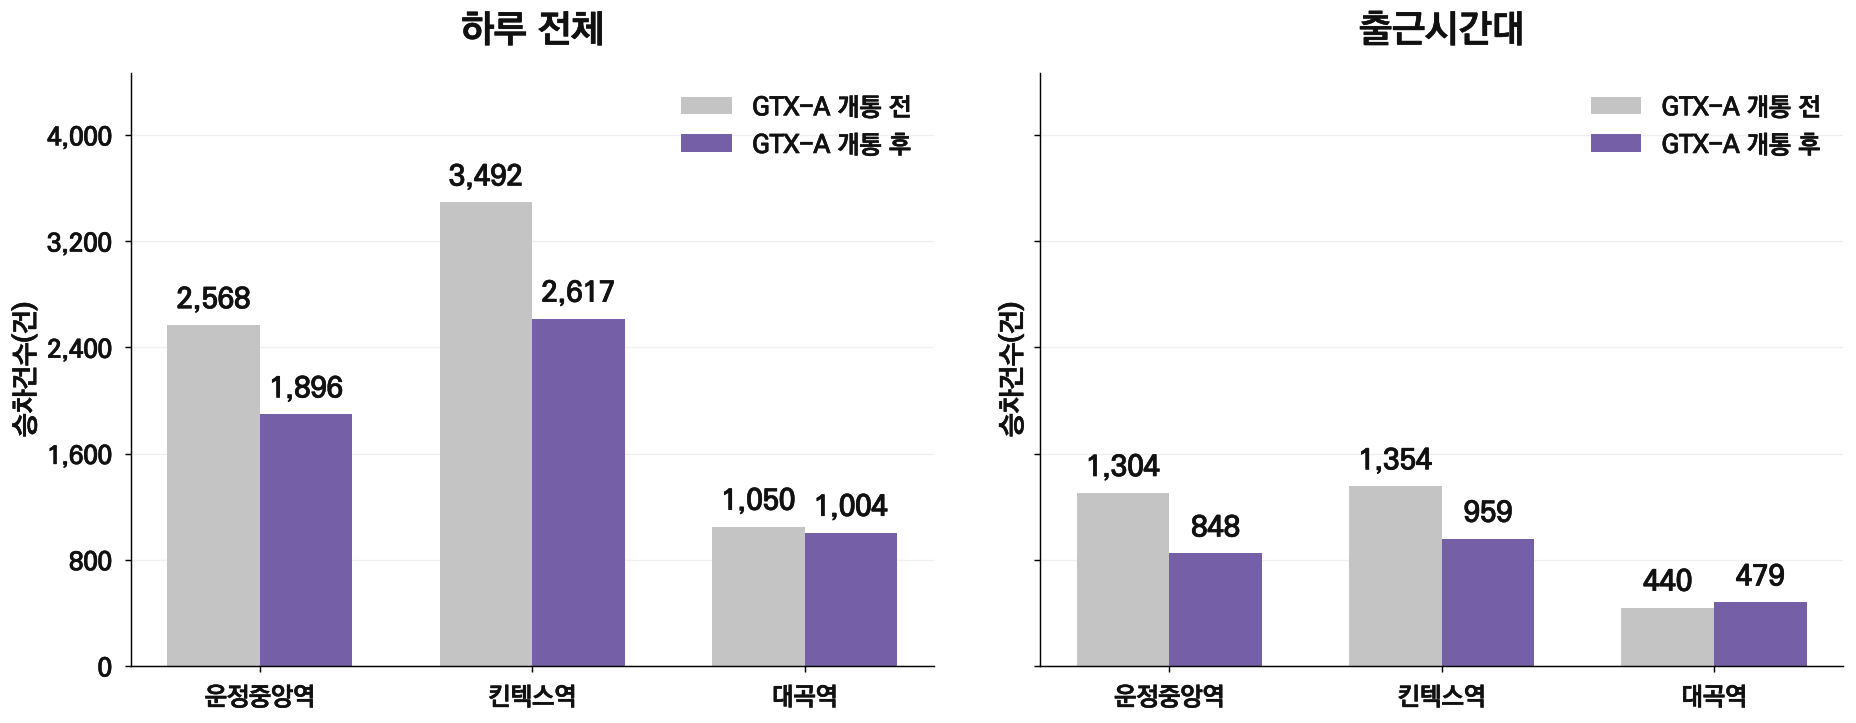

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.8), sharey=True)
x = np.arange(len(ORDER))
w = .34
limit = summary.loc[(slice(None), ORDER), ['개통 전', '개통 후']].to_numpy().max() * 1.28
for panel, (ax, period) in enumerate(zip(axes, PERIODS)):
    part = summary.loc[period].reindex(ORDER)
    for offset, key in [(-w / 2, '개통 전'), (w / 2, '개통 후')]:
        vals = part[key]
        bars = ax.bar(x + offset, vals, width=w, color=COLORS[key], label=f'GTX-A {key}')
        ax.bar_label(bars, labels=[f'{int(v):,}' for v in vals], padding=6,
                     fontsize=16, fontweight='bold')
    ax.set_xticks(x, [f'{st}역' for st in ORDER])
    ax.set_ylim(0, limit)
    ax.set_ylabel('승차건수(건)')
    ax.set_title(period, fontsize=21, fontweight='bold', pad=18)
    ax.legend(frameon=False, loc='upper right', fontsize=14)
    style_axis(ax)
fig.tight_layout(w_pad=2.6)
save_figure(fig, '그림02_권역별_광역버스_승차건수')

## 참고용 — 권역별 광역버스 승차 변화량과 변화율 (본문 미사용)

막대 높이는 변화량(건)이며 레이블은 변화량과 변화율을 함께 제시한다. 감소는 빨강, 증가는 파랑이다. 패널의 세로축 범위를 일치시켜 절대 변화량을 비교한다.


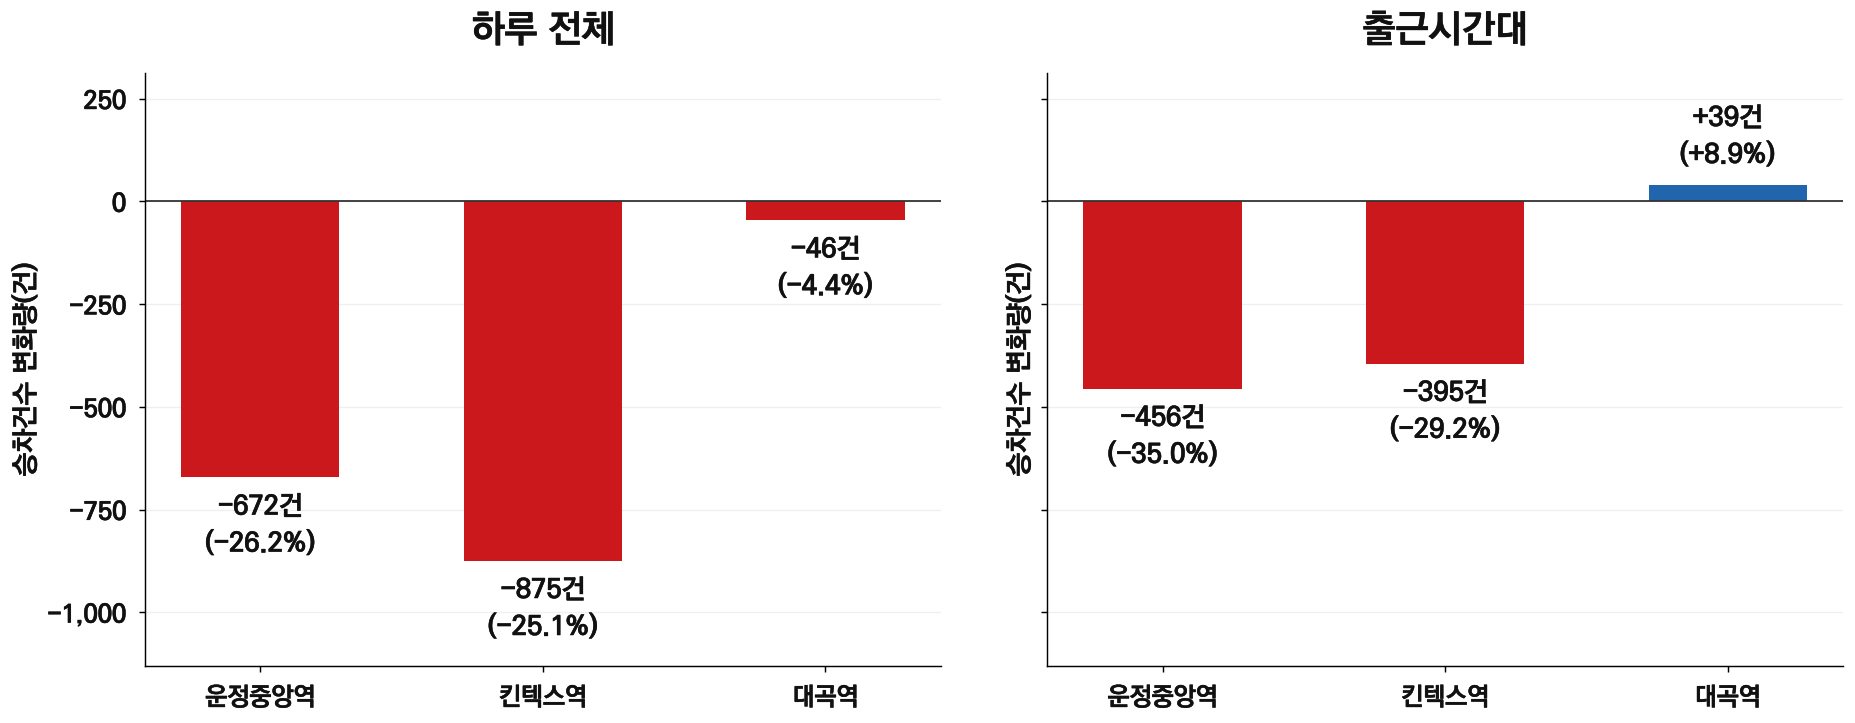

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.8), sharey=True)
all_changes = summary.loc[(slice(None), ORDER), '변화량(건)']
lower = min(0, float(all_changes.min()))
upper = max(0, float(all_changes.max()))
span = max(1, upper - lower)
for ax, period in zip(axes, PERIODS):
    part = summary.loc[period].reindex(ORDER)
    values = part['변화량(건)']
    colors = [COLORS['감소'] if v < 0 else COLORS['증가'] if v > 0 else COLORS['유지'] for v in values]
    bars = ax.bar(np.arange(len(ORDER)), values, width=.56, color=colors)
    ax.axhline(0, color='#333333', lw=1)
    ax.set_xticks(np.arange(len(ORDER)), [f'{st}역' for st in ORDER])
    ax.set_ylim(lower - span * .28, upper + span * .30)
    ax.set_ylabel('승차건수 변화량(건)')
    ax.set_title(period, fontsize=21, fontweight='bold', pad=18)
    for bar, (_, row) in zip(bars, part.iterrows()):
        value = int(row['변화량(건)'])
        ax.annotate(f'{value:+,}건\n({row["변화율(%)"]:+.1f}%)',
                    (bar.get_x() + bar.get_width() / 2, value),
                    xytext=(0, -9 if value < 0 else 9), textcoords='offset points',
                    ha='center', va='top' if value < 0 else 'bottom',
                    fontsize=15, fontweight='bold', linespacing=1.5)
    style_axis(ax)
fig.tight_layout(w_pad=2.6)
save_figure(fig, '그림03_권역별_광역버스_변화량_변화율_막대그래프')


## 그림 3 — 광역버스 승차 감소량 중 출근시간대의 비중

하루 전체 순감소량 1,593건을 출근시간대 812건(51.0%)과 그 외 시간대 781건(49.0%)으로 나눈 원그래프이다. 126개 격자를 기준으로 기존 S1 및 H11a 집계와 일치하는지 확인한다.


In [ ]:
from pathlib import Path
import runpy

reduction_share_root = next(p for p in [Path.cwd(), *Path.cwd().parents]
                            if (p / 'config.py').is_file() and (p / 'code').is_dir())
reduction_share_plot = runpy.run_path(str(
    reduction_share_root / 'code/03_eda/plot_broad_bus_reduction_share.py'))
reduction_share_plot['create_figure']()


## 3.1.2 시간대별 승차 변화 집계

전체 및 권역별 24시간 집계는 모두 보존한다. 그림은 기존 014와 동일하게 05시대부터 23시대까지 표시하며, 출근시간대는 6·7·8·9시대이다. 전년도 0건은 변화율을 산출하지 않는다. 자정 이후 기록을 임의로 삭제하지 않는다.

In [5]:
hourly_long = pd.DataFrame(hourly_frames)
hourly = hourly_long.pivot(index=['권역', '시간'], columns='연도', values='승차건수')
hourly.columns = ['2024년', '2025년']
hourly['변화량(건)'] = hourly['2025년'] - hourly['2024년']
hourly['변화율(%)'] = 100 * hourly['변화량(건)'] / hourly['2024년'].replace(0, np.nan)
for region in ['전체', *ORDER]:
    for period, hours in [('하루 전체', range(24)), ('출근시간대', range(6, 10))]:
        values = hourly.loc[region].loc[list(hours), ['2024년', '2025년']].sum()
        np.testing.assert_array_equal(values.to_numpy(), summary.loc[(period, region), ['개통 전', '개통 후']].to_numpy())
hourly.to_csv(TABLES / '3_1_2_시간대별_광역버스_승차변화.csv', encoding='utf-8-sig')
print('24시간 합계와 출근시간대 합계 모두 기존 권역별 집계와 일치')
display(hourly.loc['전체'].round(2))

24시간 합계와 출근시간대 합계 모두 기존 권역별 집계와 일치


,2024년,2025년,변화량(건),변화율(%)
시간,,,,
0,19,15,-4,-21.05
1,3,0,-3,-100.00
2,0,0,0,NaN
3,0,0,0,NaN
4,46,54,8,17.39
5,455,387,-68,-14.95
6,943,652,-291,-30.86
7,1013,778,-235,-23.20
8,695,530,-165,-23.74


## 그림 4 — 시간대별 광역버스 승차건수

개통 전 회색, 개통 후 보라색을 사용한다. 노란 배경은 출근시간대이다. 상단 전체 제목과 하단 주석은 넣지 않고, 본문 캡션으로 설명한다.

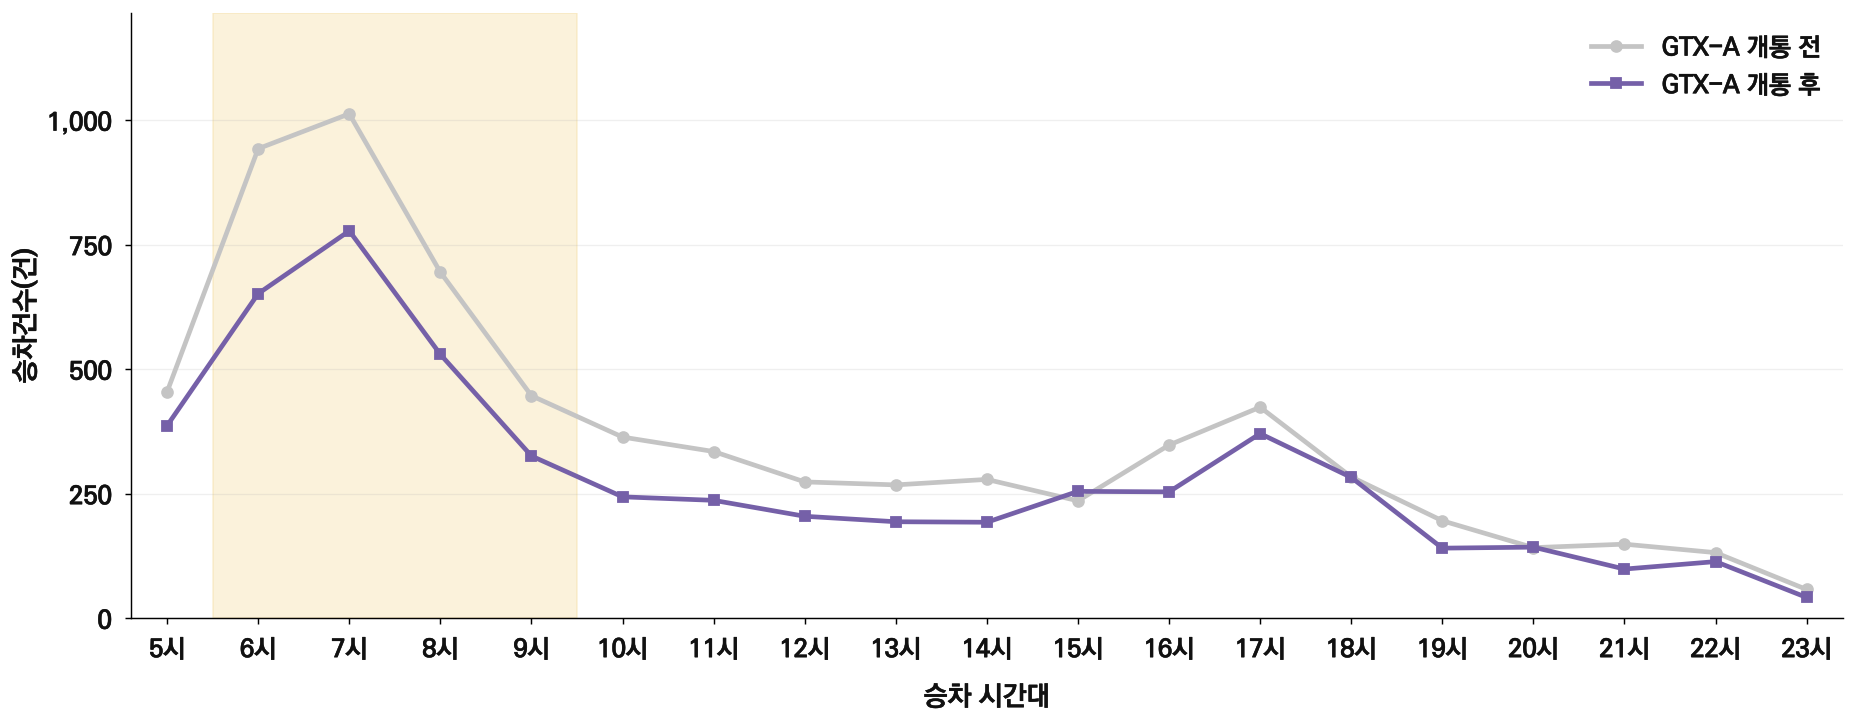

In [6]:
whole = hourly.loc['전체'].loc[5:23]
fig, ax = plt.subplots(figsize=(14.5, 5.8))
ax.axvspan(5.5, 9.5, color='#F4DA9A', alpha=.35, zorder=0)
for year, key, marker in [(2024, '개통 전', 'o'), (2025, '개통 후', 's')]:
    ax.plot(whole.index, whole[f'{year}년'], color=COLORS[key], marker=marker,
            markersize=6, linewidth=2.6, label=f'GTX-A {key}', zorder=3)
ax.set_xticks(range(5, 24), [f'{hour}시' for hour in range(5, 24)])
ax.set_xlim(4.6, 23.4)
ax.set_ylim(0, whole[['2024년', '2025년']].to_numpy().max() * 1.2)
ax.set_xlabel('승차 시간대', labelpad=12)
ax.set_ylabel('승차건수(건)')
ax.legend(frameon=False, fontsize=14, loc='upper right')
style_axis(ax)
fig.tight_layout()
save_figure(fig, '그림04_시간대별_광역버스_승차건수')

## 그림 5 — 시간대별 광역버스 승차 변화율과 변화량

막대 높이는 변화율(%), 레이블은 변화율과 변화량(건)이다. 감소 빨강, 증가 파랑을 사용한다. 분모가 0인 경우 막대를 그리지 않고 산출 불가로 표시한다.

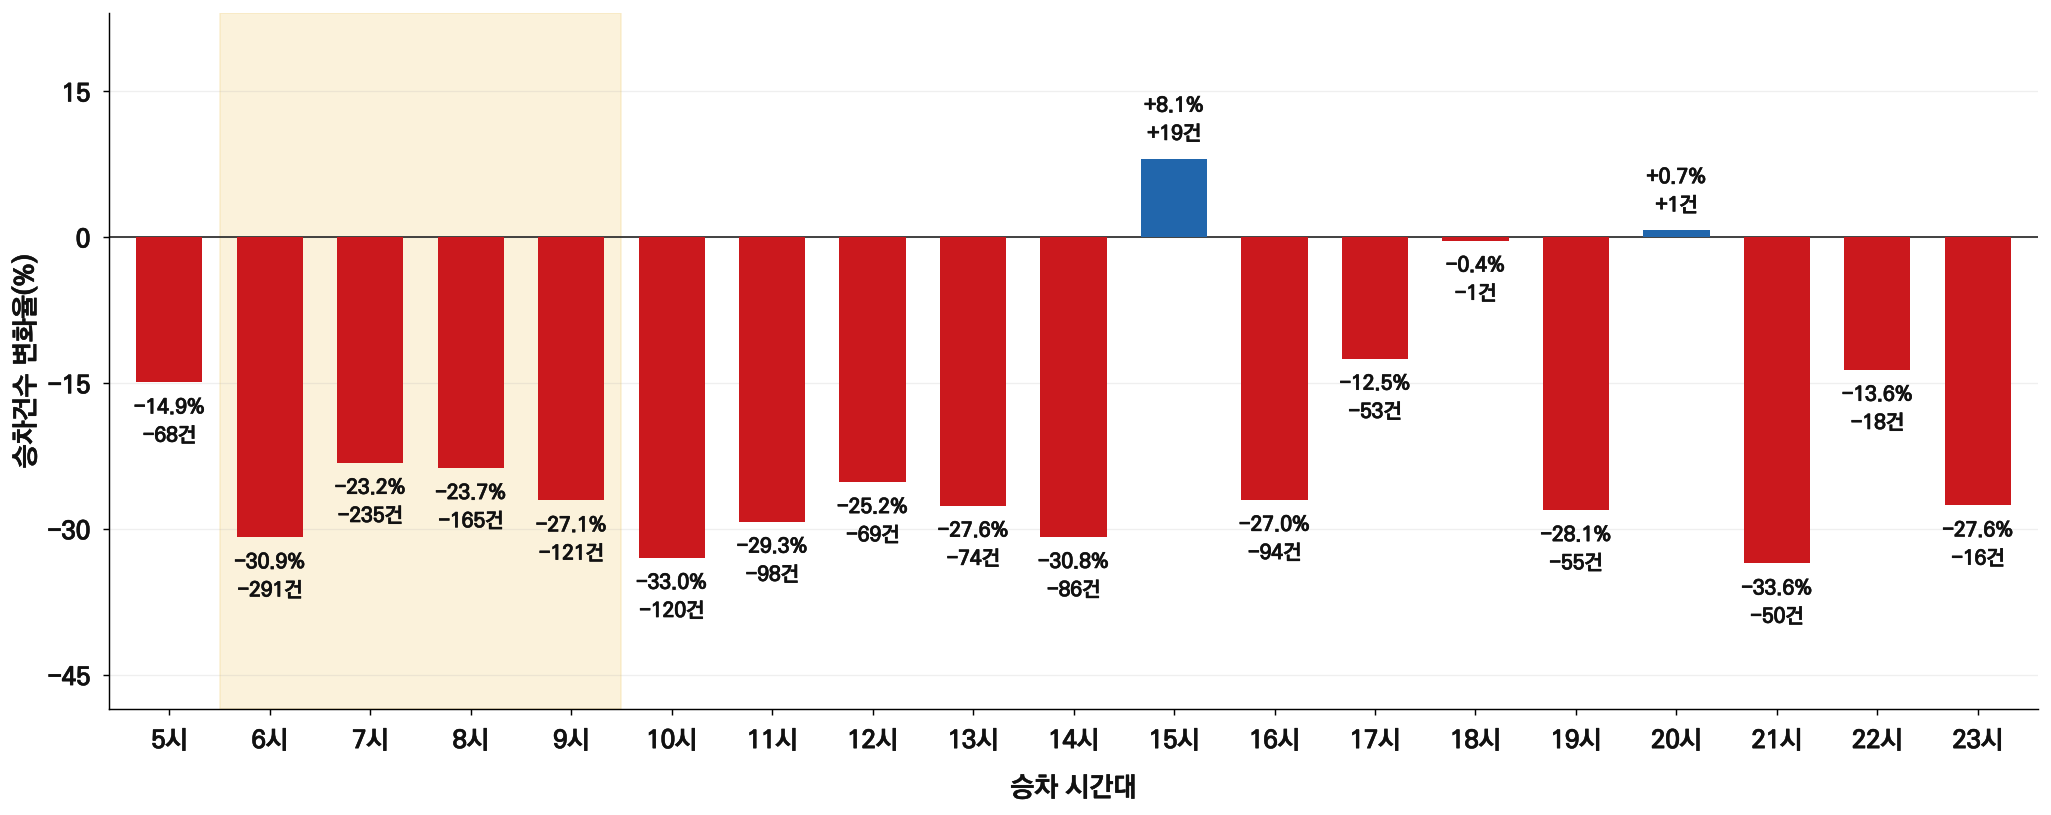

In [7]:
whole = hourly.loc['전체'].loc[5:23]
fig, ax = plt.subplots(figsize=(16, 6.5))
ax.axvspan(5.5, 9.5, color='#F4DA9A', alpha=.35, zorder=0)
values = whole['변화율(%)']
ok = values.notna()
colors = [COLORS['감소'] if v < 0 else COLORS['증가'] if v > 0 else COLORS['유지'] for v in values.loc[ok]]
ax.bar(values.index[ok], values.loc[ok], width=.66, color=colors, zorder=3)
ax.axhline(0, color='#333333', lw=1)
lo = min(0, float(values.min()))
hi = max(0, float(values.max()))
pad = max(15, (hi - lo) * .32)
ax.set_ylim(lo - pad, hi + pad)
for hour, row in whole.iterrows():
    v = row['변화율(%)']
    label = (f'{v:+.1f}%' if pd.notna(v) else '산출 불가') + f'\n{int(row["변화량(건)"]):+,}건'
    ax.annotate(label, (hour, v if pd.notna(v) else 0),
                xytext=(0, -8 if pd.notna(v) and v < 0 else 8), textcoords='offset points',
                ha='center', va='top' if pd.notna(v) and v < 0 else 'bottom',
                fontsize=11.5, fontweight='bold', linespacing=1.45)
ax.set_xticks(range(5, 24), [f'{hour}시' for hour in range(5, 24)])
ax.set_xlim(4.4, 23.6)
ax.set_xlabel('승차 시간대', labelpad=12)
ax.set_ylabel('승차건수 변화율(%)')
style_axis(ax)
ax.yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
fig.tight_layout()
save_figure(fig, '그림05_시간대별_광역버스_변화율_변화량')

## 3.1.3 격자별 승차 변화 — 시간대 비교

종일과 출근시간대의 감소·유지·증가 구분이 다른 격자만 노란 테두리로 표시한다. 변화량의 크기 차이만으로는 테두리를 표시하지 않는다. 두 지도에 공통된 감소(빨강)·유지(회색)·증가(파랑) 색상을 적용한다.


In [8]:
import geopandas as gpd
from matplotlib.patches import Patch
import math

map_admin_path = ROOT / 'data/raw/common/api_cache_gtx_a_routes/HangJeongDong_ver20260701.geojson'
map_grid_path = next((ROOT / 'data/raw/common/grid/빈격자(250m)').glob('*.shp'))
map_crs = gpd.read_file(map_grid_path, rows=1).crs
map_admin = gpd.read_file(map_admin_path).to_crs(map_crs)
map_admin['sgg_code'] = map_admin['sgg'].astype(str).str.extract(r'([0-9]+)')[0].str.zfill(5)
map_city = map_admin.loc[map_admin['sgg_code'].str.startswith(('4128', '4148'))]
map_boundary = map_city.geometry.union_all()
map_background = gpd.read_file(map_grid_path, bbox=map_boundary.bounds)
map_background = map_background.loc[map_background.geometry.intersects(map_boundary)].copy()
map_background['_key'] = map_background.geometry.apply(lambda g: g.wkb if g is not None else None)
map_background = map_background.drop_duplicates('_key').drop(columns='_key').reset_index(drop=True)
map_background['셀 ID'] = np.arange(1, len(map_background) + 1)
map_grid = map_background[['셀 ID', 'geometry']].merge(grid.reset_index(), on='셀 ID', how='inner', validate='one_to_one')
assert len(map_grid) == 126 and map_grid['셀 ID'].is_unique
centers = map_grid.set_index('셀 ID').geometry.centroid.to_crs('EPSG:4326').reindex(base.index)
# S1에 저장된 중심점과 수 cm 이내인지 확인하여 격자 ID 재현 오류를 방지한다.
np.testing.assert_allclose(centers.x, base['중심점 경도'], atol=1e-6, rtol=0)
np.testing.assert_allclose(centers.y, base['중심점 위도'], atol=1e-6, rtol=0)
map_stations = gpd.GeoDataFrame({'역명': ORDER}, geometry=gpd.points_from_xy(
    [126.728330, 126.748060, 126.811024], [37.716670, 37.665000, 37.631626]), crs='EPSG:4326').to_crs(map_crs)
map_outline = gpd.GeoDataFrame(geometry=[map_boundary], crs=map_crs)
map_reds = ['#67000D', '#CB181D', '#FB6A4A', '#FEE0D2']
map_handles = {}; map_records = []; map_count_rows = []; map_top_rows = []
for period, prefix in zip(PERIODS, ['board', 'morning']):
    values = map_grid[f'{prefix}_2025'] - map_grid[f'{prefix}_2024']
    map_grid[f'{prefix}_change'] = values
    edges = values.quantile([.25, .50, .75]).to_numpy()
    codes = np.searchsorted(edges, values, side='left')
    map_grid[f'{prefix}_color'] = ['#2166AC' if v > 0 else '#EEEEEE' if v == 0 else map_reds[int(c)] for v, c in zip(values, codes)]
    handles = []
    for i, color in enumerate(map_reds):
        lower = None if i == 0 else math.floor(edges[i-1]) + 1
        upper = min(math.floor(edges[i]), -1) if i < 3 else -1
        if lower is not None and lower > upper:
            continue
        label = f'{upper}건 이하' if lower is None else f'{lower}건' if lower == upper else f'{lower}~{upper}건'
        handles.append(Patch(facecolor=color, edgecolor='#333333', label=label))
        mask = values.le(upper) if lower is None else values.between(lower, upper)
        map_records.append({'시간대':period, '범위':label, '격자 수':int(mask.sum())})
    for label, color, mask in [('0건 (유지)', '#EEEEEE', values.eq(0)), ('+1건 이상', '#2166AC', values.gt(0))]:
        handles.append(Patch(facecolor=color, edgecolor='#333333', label=label))
        map_records.append({'시간대':period, '범위':label, '격자 수':int(mask.sum())})
    map_handles[period] = handles
    for st in [*ORDER, '전체']:
        part = map_grid if st == '전체' else map_grid.loc[map_grid['nearest_station'].eq(st)]
        change = part[f'{prefix}_change']
        map_count_rows.append({'시간대':period, '권역':st, '감소':int(change.lt(0).sum()), '유지':int(change.eq(0).sum()), '증가':int(change.gt(0).sum()), '합계':len(part)})
        if st != '전체':
            top = part.loc[change.lt(0)].sort_values([f'{prefix}_change', '셀 ID'], kind='stable').head(3)
            for rank, (_, row) in enumerate(top.iterrows(), 1):
                map_top_rows.append({'시간대':period, '권역':st, '감소 순위':rank, '셀 ID':int(row['셀 ID']), '개통 전':int(row[f'{prefix}_2024']), '개통 후':int(row[f'{prefix}_2025']), '변화량':int(row[f'{prefix}_change'])})
    print(period, '사분위 경계:', edges.tolist())
map_counts = pd.DataFrame(map_count_rows)
assert map_counts.loc[map_counts['권역'].eq('전체'), '합계'].eq(126).all()
assert pd.DataFrame(map_records).groupby('시간대')['격자 수'].sum().eq(126).all()
map_counts.to_csv(TABLES / '3_1_3_권역별_감소_유지_증가_격자수.csv', index=False, encoding='utf-8-sig')
pd.DataFrame(map_records).to_csv(TABLES / '3_1_3_지도_색상범위.csv', index=False, encoding='utf-8-sig')
pd.DataFrame(map_top_rows).to_csv(TABLES / '3_1_3_권역별_감소상위3_격자.csv', index=False, encoding='utf-8-sig')
map_grid.drop(columns='geometry').to_csv(TABLES / '3_1_3_격자별_승차건수_변화량.csv', index=False, encoding='utf-8-sig')
display(map_counts)

하루 전체 사분위 경계: [-13.75, -3.0, 1.0]
출근시간대 사분위 경계: [-7.75, -1.5, 1.0]


,시간대,권역,감소,유지,증가,합계
0,하루 전체,운정중앙,39,6,18,63
1,하루 전체,킨텍스,20,1,5,26
2,하루 전체,대곡,17,8,12,37
3,하루 전체,전체,76,15,35,126
4,출근시간대,운정중앙,38,10,15,63
5,출근시간대,킨텍스,20,1,5,26
6,출근시간대,대곡,15,5,17,37
7,출근시간대,전체,73,16,37,126


## 그림 6·9·12 — 하루 전체·출근시간대 통합 격자 지도

각 격자의 왼쪽 절반은 하루 전체, 오른쪽 절반은 출근시간대를 나타낸다. 변화 구분이 다른 격자만 노란 테두리로 표시하며 수치는 표시하지 않는다. 운정중앙과 대곡은 주요 격자 분포를 확대하고 작은 전체 지도에서 확대 위치를 확인한다. 카카오맵은 기존 이미지를 유지한다.


In [9]:
import importlib.util
comparison_path = ROOT / 'code/03_eda/kakao_period_compare.py'
spec = importlib.util.spec_from_file_location('kakao_period_compare', comparison_path)
comparison = importlib.util.module_from_spec(spec)
spec.loader.exec_module(comparison)
comparison_grid, comparison_summary = comparison.prepare_comparison(map_grid, TABLES)
comparison_payload = comparison.make_payload(comparison_grid, map_stations, TABLES)
display(comparison_summary)
# 카카오맵 실행: 별도 터미널에서 아래 명령 실행 후 키를 입력한다.
# python code/03_eda/kakao_period_compare.py --port 8765
# http://localhost:8765/compare?station=운정중앙
# http://localhost:8765/compare?station=킨텍스
# http://localhost:8765/compare?station=대곡


,격자수,구분변경,증감반전,유지포함변경
nearest_station,,,,
운정중앙,63,16,4,12
킨텍스,26,2,2,0
대곡,37,9,2,7
전체,126,27,8,19


## 그림 8·11·14 — 권역별 현장답사 사진

중간발표 PPT의 사진 원본을 추출하여 사용한다. PPT에 설정된 회전만 반영하고 원본의 가로세로 비율을 유지한다. 운정중앙은 감소 격자 주변 아파트 단지·정류장, 킨텍스는 상가·고양종합운동장과 역 주변 아파트·킨텍스, 대곡은 증가 격자 주변 아파트 단지만 제시한다. 운정중앙 환승센터·주차장과 대곡역 출입구 사진은 같은 원본 폴더에 4장 비교용으로 보관한다.


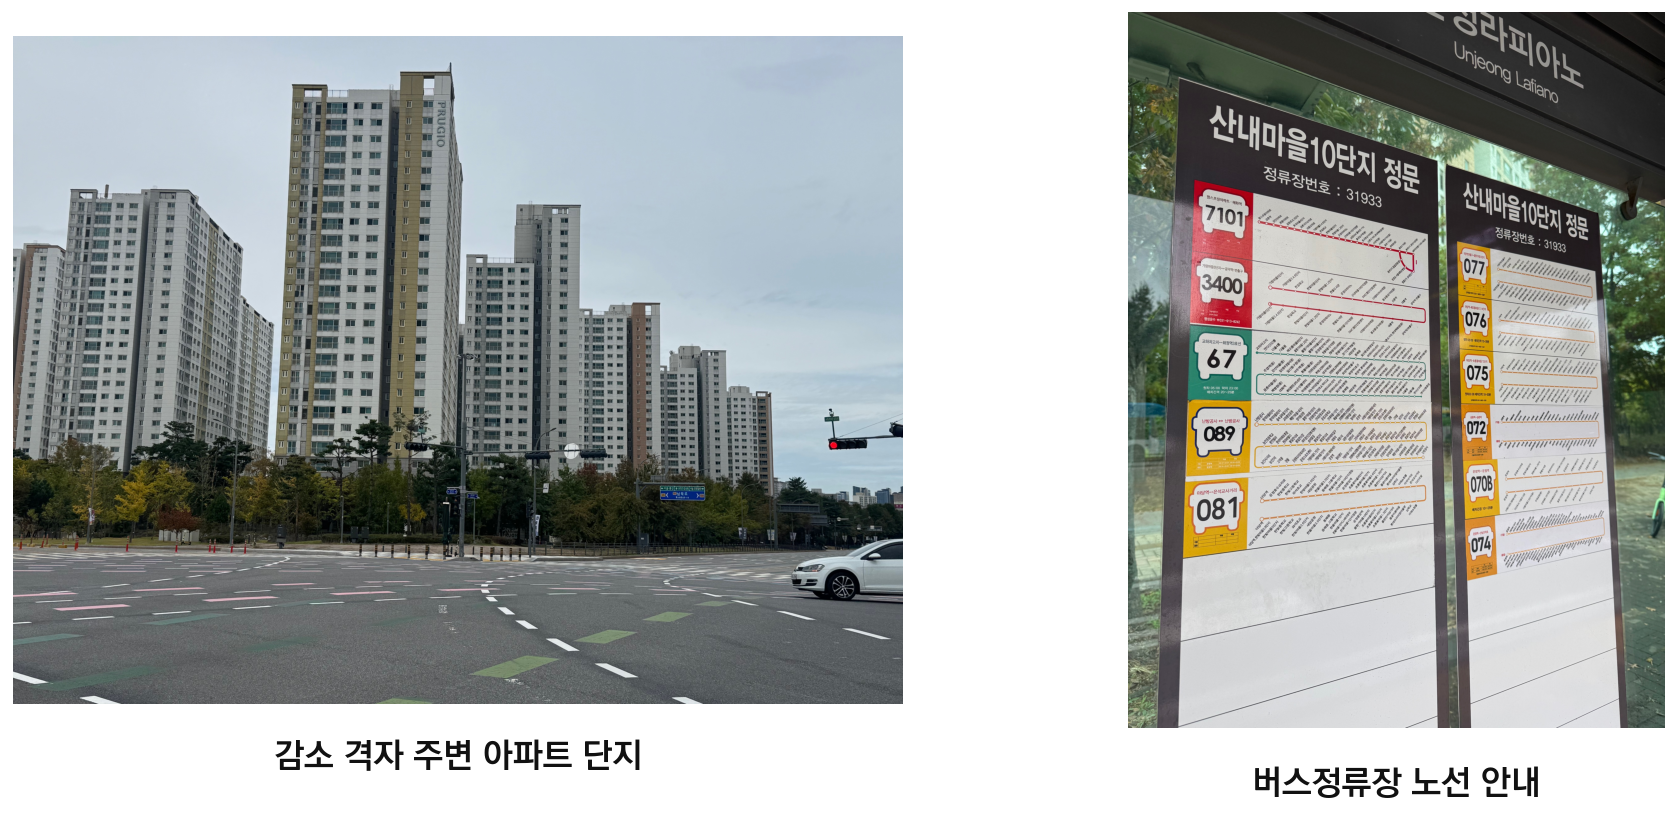

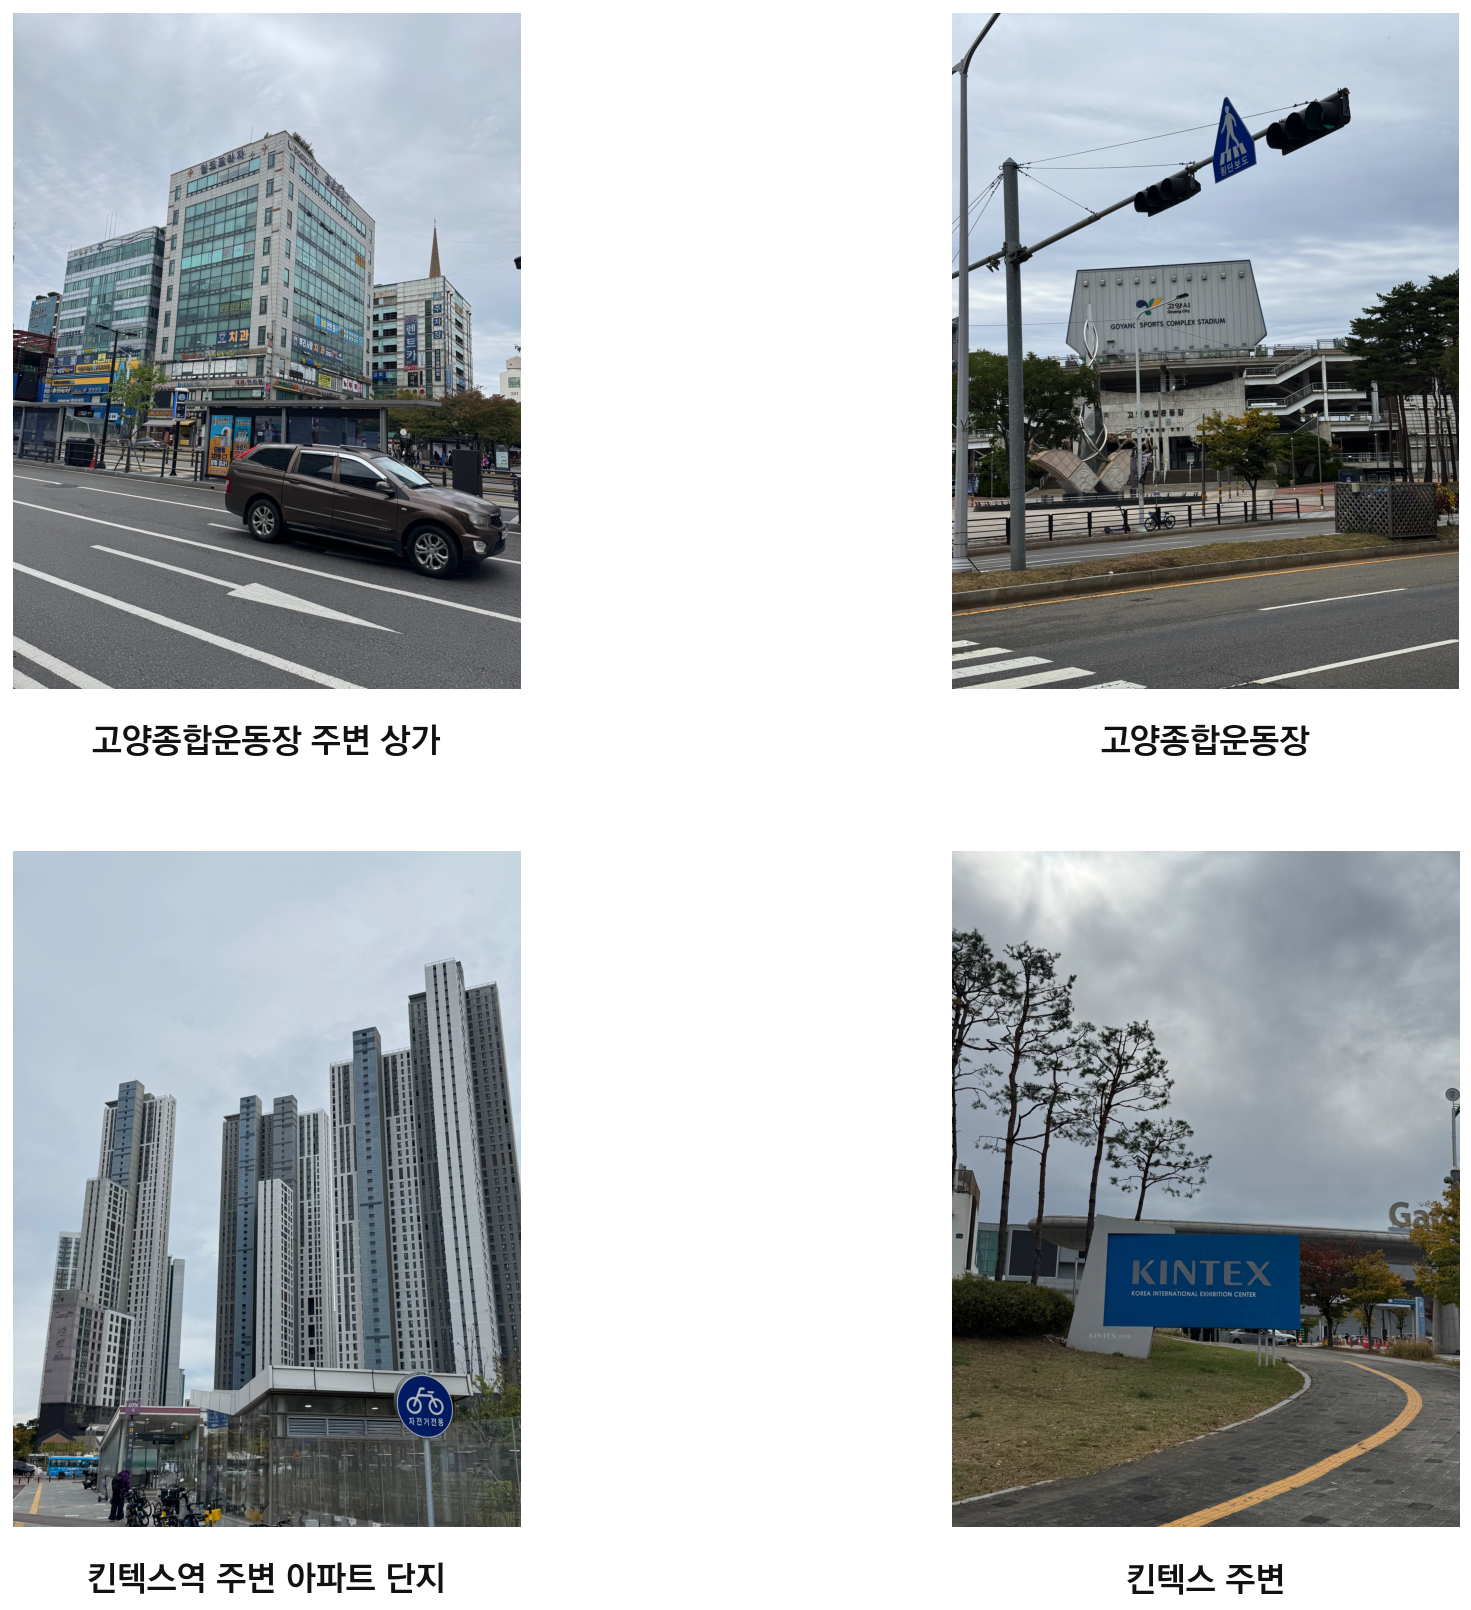

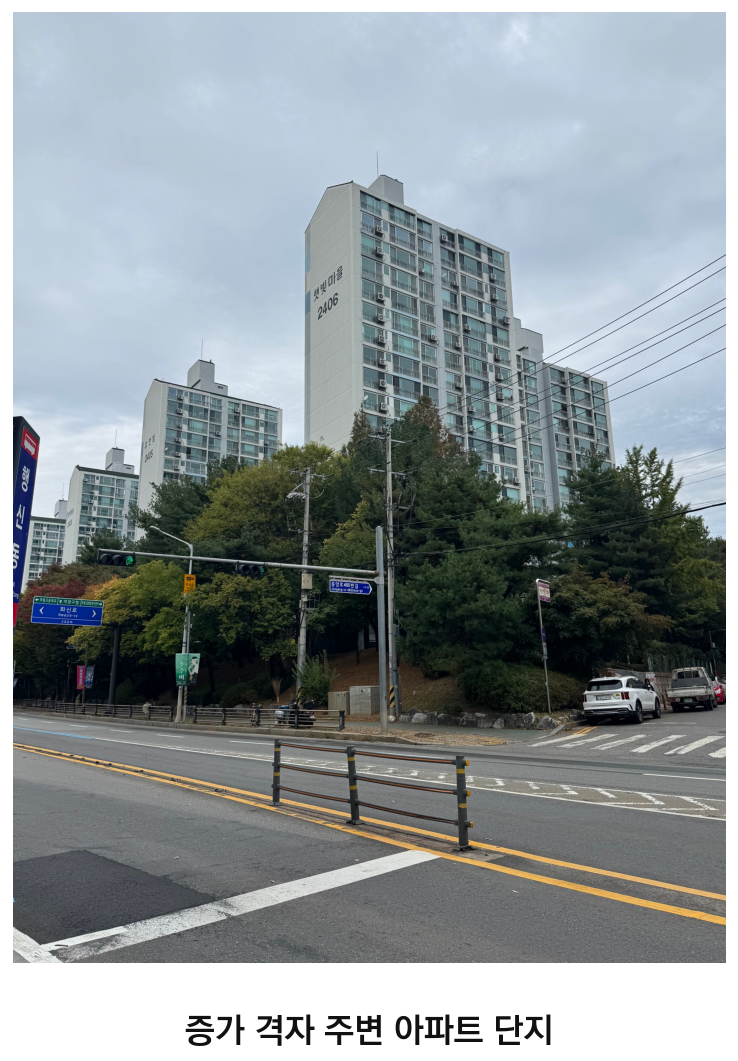

In [10]:
import json

visit_root = ROOT / 'results/paper/sources/3_1_3_현장답사'
visit_manifest = json.loads((visit_root / '출처.json').read_text())
visit_rotations = {item['사진파일']: item['시계방향회전'] for item in visit_manifest}
visit_sets = [
    ('운정중앙', 8, [
        ('s18_p1.jpeg', '감소 격자 주변 아파트 단지'),
        ('s18_p2.jpeg', '버스정류장 노선 안내')]),
    ('킨텍스', 11, [
        ('s20_p1.jpeg', '고양종합운동장 주변 상가'),
        ('s20_p2.png', '고양종합운동장'),
        ('s21_p1.jpeg', '킨텍스역 주변 아파트 단지'),
        ('s21_p2.jpeg', '킨텍스 주변')]),
    ('대곡', 14, [
        ('s23_p2.jpeg', '증가 격자 주변 아파트 단지')]),
]
for station, number, pictures in visit_sets:
    rows = 2 if len(pictures) == 4 else 1
    columns = 1 if len(pictures) == 1 else 2
    size = (7.2, 8.5) if columns == 1 else (14.5, 6.4 * rows)
    fig, axes = plt.subplots(rows, columns, figsize=size, squeeze=False)
    for ax, (filename, label) in zip(axes.flat, pictures):
        photo = plt.imread(visit_root / filename)
        angle = visit_rotations[filename]
        if angle:
            photo = np.rot90(photo, k=-angle // 90)
        ax.imshow(photo)
        ax.set_axis_off()
        ax.text(.5, -.055, label, transform=ax.transAxes, ha='center', va='top',
                fontsize=19, fontweight='bold', color='#111111')
    fig.subplots_adjust(left=.015, right=.985, top=.98, bottom=.12 if rows == 1 else .07,
                        wspace=.055, hspace=.24)
    stem = f'그림{number:02d}_{station}_증가격자_현장답사' if station == '대곡' else f'그림{number:02d}_{station}_현장답사'
    save_figure(fig, stem)


## 통합 격자 지도 생성

논문 본문에 사용할 통합 지도 3장을 PNG와 PDF로 저장한다. 기존의 나란히 비교하는 지도는 재생성하지 않는다.


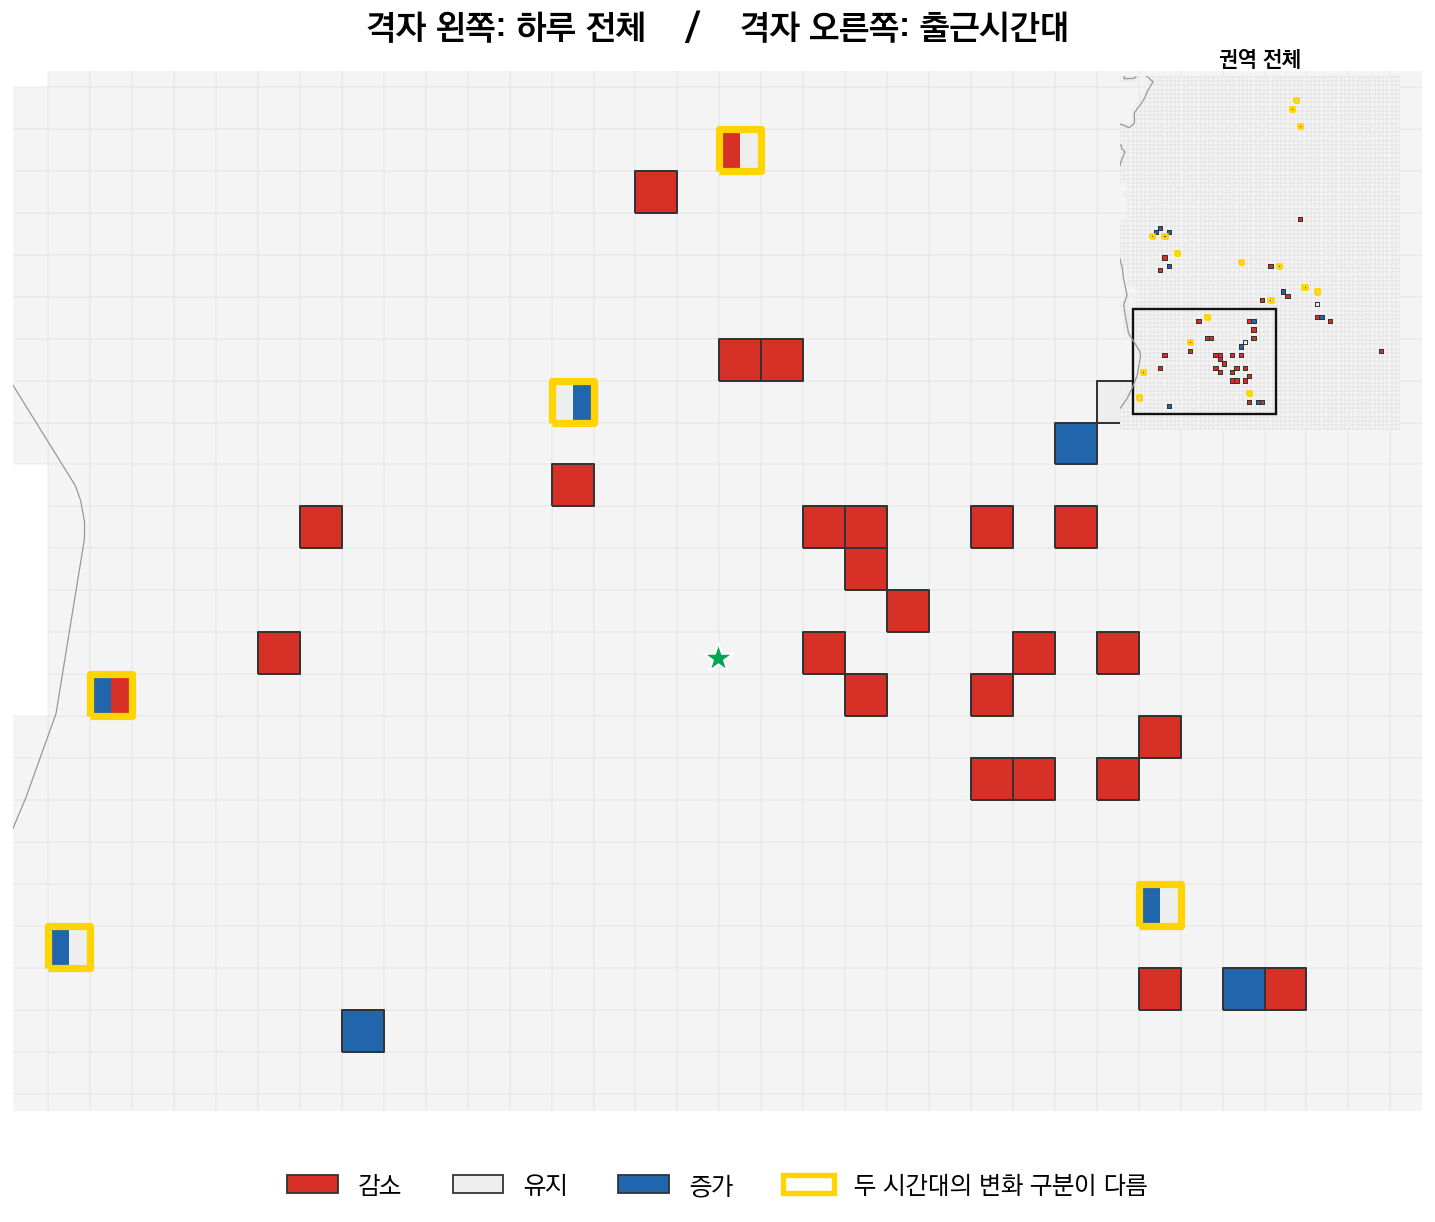

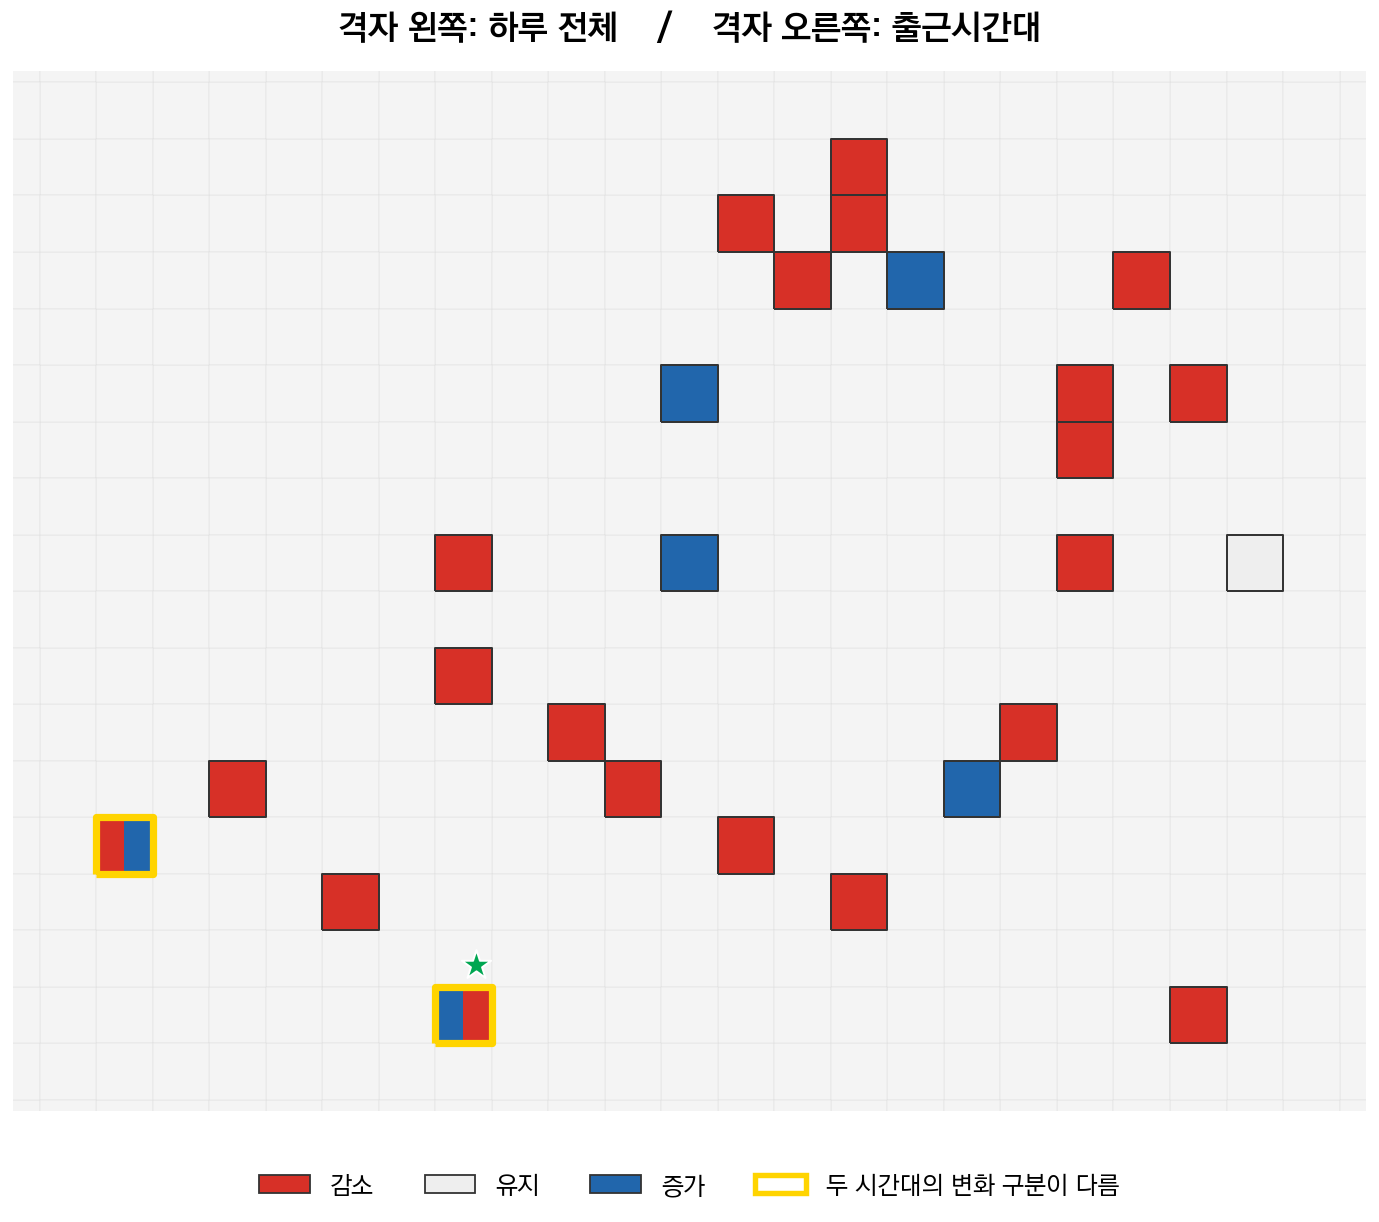

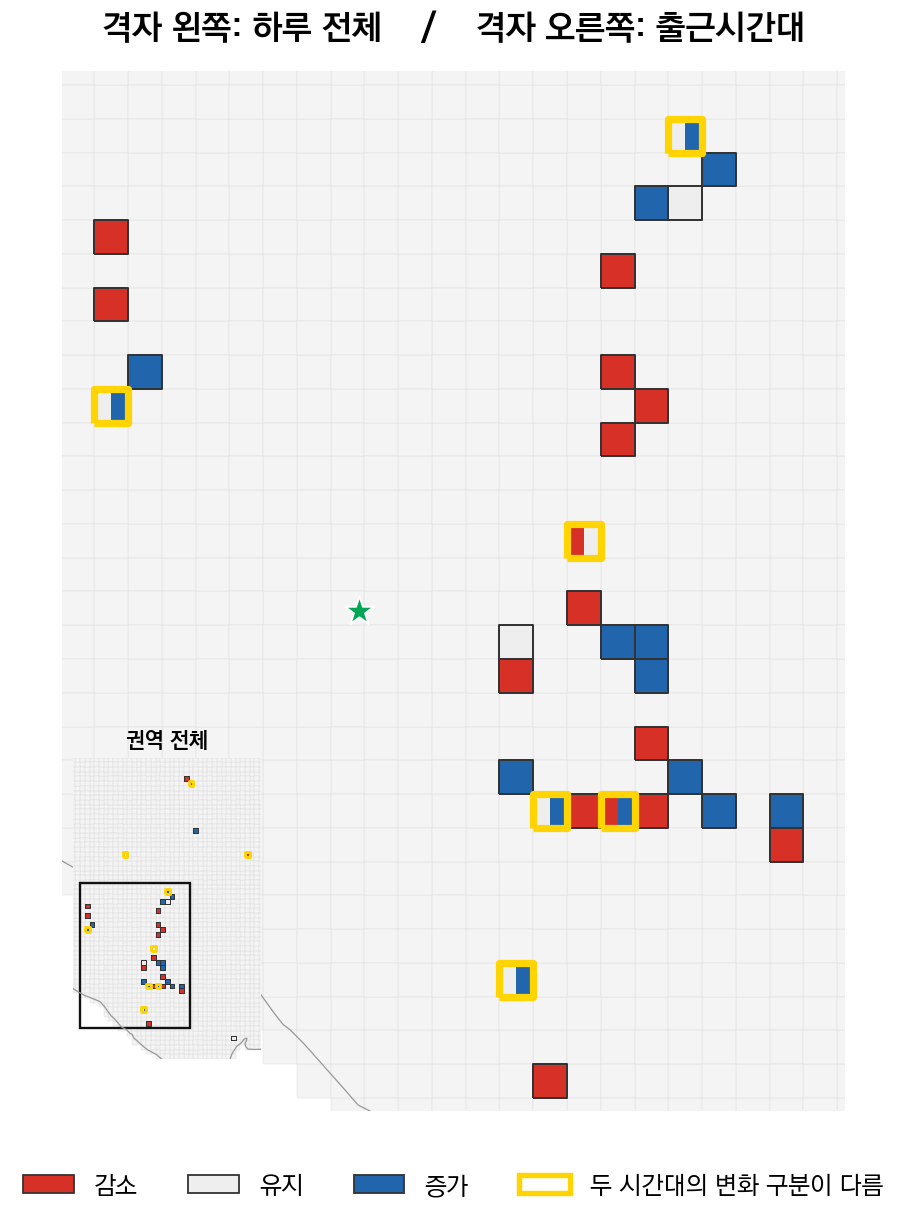

In [11]:
comparison.render_combined(comparison_grid, map_stations, map_background, map_outline, TABLES, save_figure)


## 참고용 — 하루 전체·출근시간대 광역버스 회귀계수 비교 (본문 미사용)

3.2.4의 시간대별 결과 비교용 그림이다. 동일한 113개 격자의 기존 회귀계수와 95% 신뢰구간을 사용한다. 독립변수별 가로축 범위를 따로 적용하며, 채운 점은 5% 유의, 빈 점은 비유의를 나타낸다. 원 모형과 기존 그림은 수정하지 않는다.


In [ ]:
from pathlib import Path
import runpy

coefficient_root = next(p for p in [Path.cwd(), *Path.cwd().parents]
                        if (p / 'config.py').is_file() and (p / 'code').is_dir())
coefficient_plot = runpy.run_path(str(
    coefficient_root / 'code/03_eda/plot_broad_bus_coefficient_comparison.py'))
coefficient_plot['create_figure']()


## 그림 15 — 권역별 GTX역 연계버스 승차건수

3.3.1에 사용할 그림이다. 기초통계의 공통 범위인 126개 격자를 사용하며, 2025년 11월 6일의 하루 전체와 출근시간대 승차건수를 집계한다. 두 패널의 세로축 범위를 일치시키고 숫자와 글자를 굵게 표시한다.


In [ ]:
from pathlib import Path
import runpy

feeder_summary_root = next(p for p in [Path.cwd(), *Path.cwd().parents]
                          if (p / 'config.py').is_file() and (p / 'code').is_dir())
feeder_summary_plot = runpy.run_path(str(
    feeder_summary_root / 'code/03_eda/plot_feeder_region_summary.py'))
feeder_region_summary = feeder_summary_plot['create_figure']()
display(feeder_region_summary.round(2))


### 그림 16 GTX역 연계버스 승차건수 중 출근시간대의 비중
126개 분석격자의 개통 후 하루 전체 승차건수를 출근시간대와 그 외 시간대로 구분한다.

In [ ]:
from pathlib import Path
import sys
_share_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.py").is_file() and (p / "code").is_dir())
_share_module_path = str(_share_root / "code/03_eda")
if _share_module_path not in sys.path:
    sys.path.insert(0, _share_module_path)
from plot_feeder_morning_share import create_figure as create_feeder_morning_share
create_feeder_morning_share(show=True)
